In [42]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

# ml tools
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# dl tools
#Sequential model => initialize our ANN
# Dense Model => to build the layers
import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense


from sklearn.metrics import accuracy_score,confusion_matrix

In [10]:
churn_data=pd.read_csv('churn.csv',index_col='RowNumber')

In [11]:
churn_data.head()

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
RowNumber,,,,,,,,,,,,,
1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [13]:
churn_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10000 entries, 1 to 10000
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerId       10000 non-null  int64  
 1   Surname          10000 non-null  object 
 2   CreditScore      10000 non-null  int64  
 3   Geography        10000 non-null  object 
 4   Gender           10000 non-null  object 
 5   Age              10000 non-null  int64  
 6   Tenure           10000 non-null  int64  
 7   Balance          10000 non-null  float64
 8   NumOfProducts    10000 non-null  int64  
 9   HasCrCard        10000 non-null  int64  
 10  IsActiveMember   10000 non-null  int64  
 11  EstimatedSalary  10000 non-null  float64
 12  Exited           10000 non-null  int64  
dtypes: float64(2), int64(8), object(3)
memory usage: 1.1+ MB


In [15]:
churn_data.isnull().sum()

CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [16]:
churn_data.duplicated().sum()

np.int64(0)

In [17]:
churn_data.drop(['CustomerId','Surname'],axis=1,inplace=True)

In [18]:
churn_data.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
RowNumber,,,,,,,,,,,
1,619,France,Female,42,2,0.00,1,1,1,101348.88,1
2,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
3,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
4,699,France,Female,39,1,0.00,2,0,0,93826.63,0
5,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [19]:
churn_data['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [20]:
churn_data['Geography']= churn_data['Geography'].map({'France':0,'Germany':1,'Spain':2})

In [21]:
churn_data['Gender']= churn_data['Gender'].map({'Female':0,'Male':1})

In [22]:
churn_data.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
RowNumber,,,,,,,,,,,
1,619,0,0,42,2,0.00,1,1,1,101348.88,1
2,608,2,0,41,1,83807.86,1,0,1,112542.58,0
3,502,0,0,42,8,159660.80,3,1,0,113931.57,1
4,699,0,0,39,1,0.00,2,0,0,93826.63,0
5,850,2,0,43,2,125510.82,1,1,1,79084.10,0


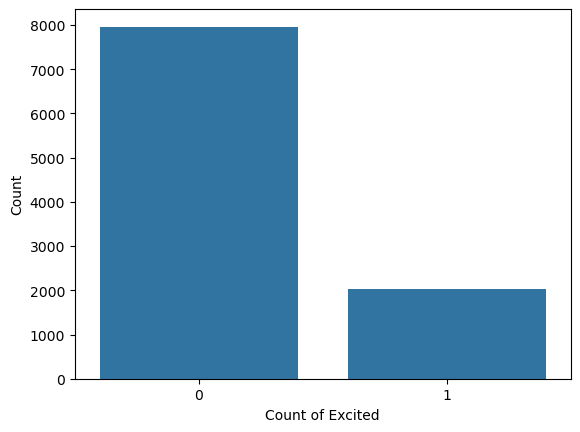

In [23]:
sns.countplot(x=churn_data['Exited'])
plt.xlabel('Count of Excited')
plt.ylabel('Count')
plt.show()

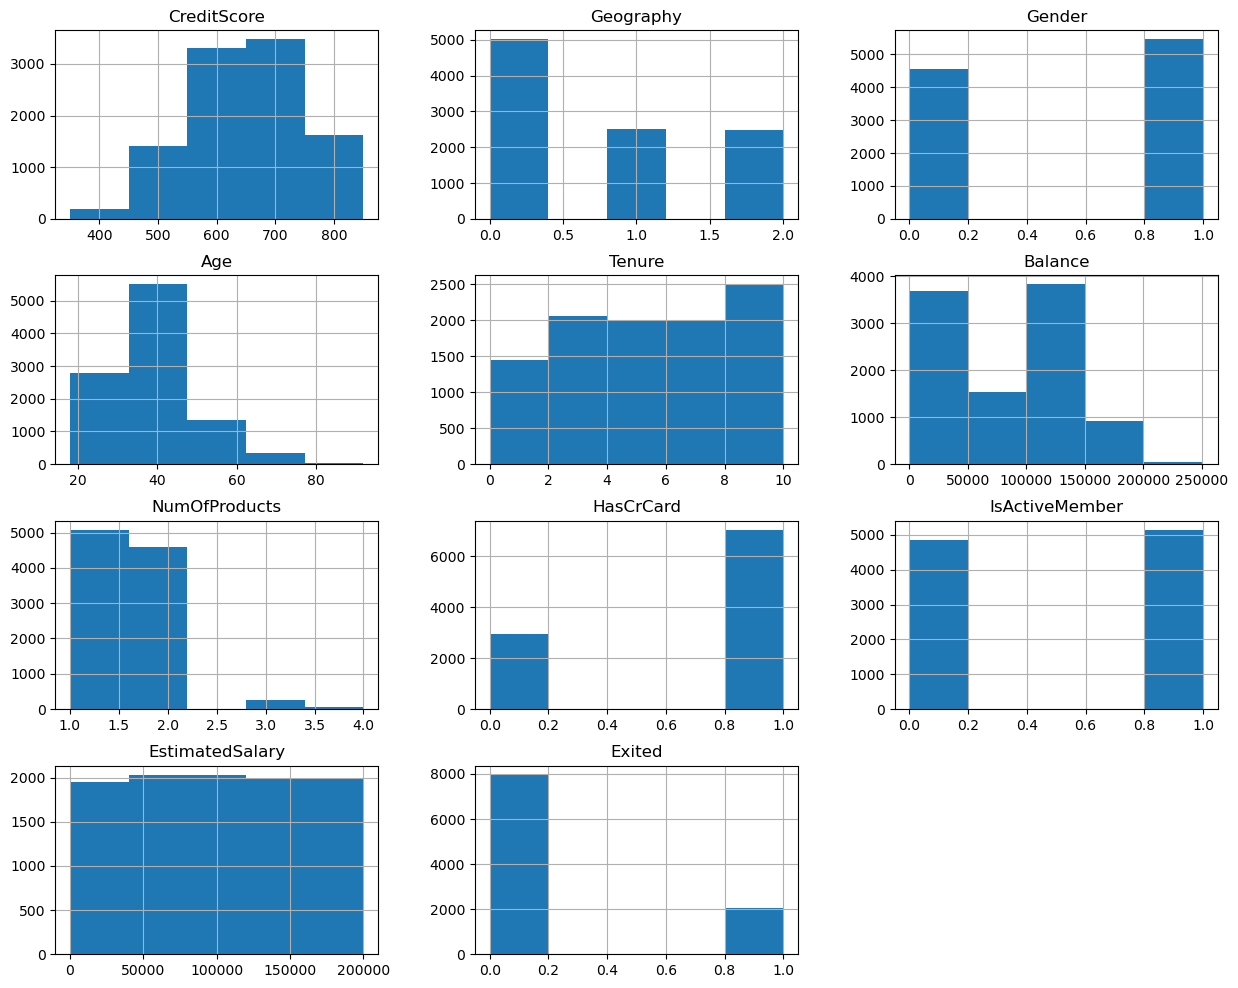

In [24]:
# distribution of all feature
churn_data.hist(figsize=(15,12),bins=5)
plt.title('Features of Distribution')
plt.show()

In [27]:
x=churn_data.drop(['Exited'],axis=1)
y=churn_data['Exited']

In [28]:
x

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
RowNumber,,,,,,,,,,
1,619,0,0,42,2,0.00,1,1,1,101348.88
2,608,2,0,41,1,83807.86,1,0,1,112542.58
3,502,0,0,42,8,159660.80,3,1,0,113931.57
4,699,0,0,39,1,0.00,2,0,0,93826.63
5,850,2,0,43,2,125510.82,1,1,1,79084.10
...,...,...,...,...,...,...,...,...,...,...
9996,771,0,1,39,5,0.00,2,1,0,96270.64
9997,516,0,1,35,10,57369.61,1,1,1,101699.77
9998,709,0,0,36,7,0.00,1,0,1,42085.58


In [29]:
y

RowNumber
1        1
2        0
3        1
4        0
5        0
        ..
9996     0
9997     0
9998     1
9999     1
10000    0
Name: Exited, Length: 10000, dtype: int64

In [30]:
X_train,X_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [32]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(8000, 10)
(8000,)
(2000, 10)
(2000,)


In [34]:
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.fit_transform(X_test)

In [35]:
X_train_scaled

array([[ 0.35649971, -0.9055496 ,  0.91324755, ...,  0.64920267,
         0.97481699,  1.36766974],
       [-0.20389777,  0.30164867,  0.91324755, ...,  0.64920267,
         0.97481699,  1.6612541 ],
       [-0.96147213,  1.50884694,  0.91324755, ...,  0.64920267,
        -1.02583358, -0.25280688],
       ...,
       [ 0.86500853, -0.9055496 , -1.09499335, ..., -1.54035103,
        -1.02583358, -0.1427649 ],
       [ 0.15932282, -0.9055496 ,  0.91324755, ...,  0.64920267,
        -1.02583358, -0.05082558],
       [ 0.47065475,  0.30164867,  0.91324755, ...,  0.64920267,
         0.97481699, -0.81456811]], shape=(8000, 10))

In [36]:
X_test_scaled

array([[-0.51250172,  0.32653736,  0.90911166, ..., -1.57810057,
        -1.0502616 , -0.99096946],
       [-0.2360466 , -0.88735616,  0.90911166, ...,  0.63367318,
         0.95214374,  0.8293793 ],
       [-0.46130633,  1.54043088, -1.09997489, ...,  0.63367318,
        -1.0502616 , -0.69904548],
       ...,
       [ 0.85953481, -0.88735616, -1.09997489, ...,  0.63367318,
        -1.0502616 , -1.13742992],
       [ 0.47044982, -0.88735616,  0.90911166, ...,  0.63367318,
        -1.0502616 , -0.38237688],
       [-0.18485121,  0.32653736,  0.90911166, ...,  0.63367318,
         0.95214374,  0.15573964]], shape=(2000, 10))

In [38]:
model=Sequential([
    Dense(units=6,kernel_initializer='uniform',activation='relu'),
    Dense(units=6,kernel_initializer ='uniform',activation='relu'),
    Dense(units=1,kernel_initializer='uniform',activation='sigmoid'),
])


In [39]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [40]:
history=model.fit(X_train,y_train,batch_size=10,epochs=100,verbose=1)

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7891 - loss: 0.5802
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7945 - loss: 0.5251
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7945 - loss: 0.5127
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7945 - loss: 0.5084
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7945 - loss: 0.5063
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7945 - loss: 0.5045
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7945 - loss: 0.5042
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7945 - loss: 0.5021
Epoch 9/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7945 - loss: 0.5032
Epoch 10/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7945 - loss: 0.5025
Epoch 11/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7945 - loss: 0.5023
Epoch 12/100
800/800 ━━━━━━━━━━━━━━━━━━━━

In [41]:
model.evaluate(X_test,y_test,batch_size=10)

200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8035 - loss: 0.4889


[0.488915354013443, 0.8034999966621399]

In [43]:
y_pred=model.predict(X_test)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [44]:
y_pred

array([[0.24131233],
       [0.13910654],
       [0.13910654],
       ...,
       [0.13910654],
       [0.13910654],
       [0.24131233]], shape=(2000, 1), dtype=float32)

In [45]:
y_pred=(y_pred>0.5).astype(int)

In [46]:
y_pred

array([[0],
       [0],
       [0],
       ...,
       [0],
       [0],
       [0]], shape=(2000, 1))

In [47]:
accuracy_score(y_test,y_pred)

0.8035

In [48]:
cnn=confusion_matrix(y_test,y_pred)

<Axes: >

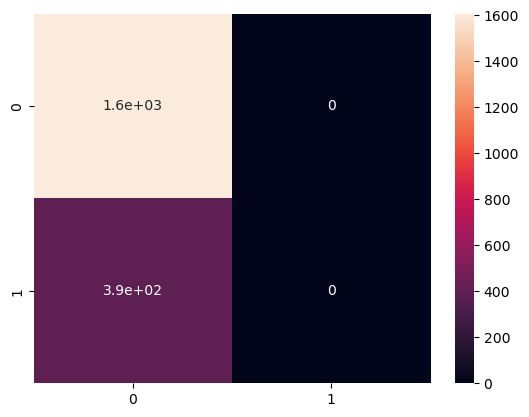

In [49]:
sns.heatmap(pd.DataFrame(cnn),annot=True)

In [52]:
X_test_reshaped = X_test.iloc[5].values.reshape(1, -1)

result = model.predict(X_test_reshaped)
result=(result>0.5).astype(int)
print(result)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step
[[0]]


In [53]:
y_test.iloc[5]

np.int64(0)

In [54]:
# PREDICTIVE SYSTEM
def pred(CreditScore, Geography, Gender, Age, Tenure, Balance, NumOfProducts, HasCrCard, IsActiveMember, EstimatedSalary):
    features = np.array([CreditScore, Geography, Gender, Age, Tenure, Balance, NumOfProducts, HasCrCard, IsActiveMember, EstimatedSalary])
    features = features.reshape(1, -1)  # Reshape to (1, input_dim)
    result = model.predict(features)
    result = (result > 0.5).astype(int)
    return result

In [55]:
if result == 1:
    print("Churn")
else:
    print("Not Churn")

Not Churn


In [56]:
# Example usage:
CreditScore = 619
Geography = 0
Gender = 0
Age = 42
Tenure = 2
Balance = 0.0
NumOfProducts = 1
HasCrCard = 1
IsActiveMember = 1
EstimatedSalary = 101348.88

result = pred(CreditScore, Geography, Gender, Age, Tenure, Balance, NumOfProducts, HasCrCard, IsActiveMember, EstimatedSalary)
print(result)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
[[0]]


In [57]:
churn_data.iloc[0]

CreditScore           619.00
Geography               0.00
Gender                  0.00
Age                    42.00
Tenure                  2.00
Balance                 0.00
NumOfProducts           1.00
HasCrCard               1.00
IsActiveMember          1.00
EstimatedSalary    101348.88
Exited                  1.00
Name: 1, dtype: float64